# 02 — Exploratory Data Analysis

Pipeline stage 2 of 5.

Loads `cleaned_reports.pkl` and produces every plot from the original monolith:
- Label distribution
- Severity
- Target sector
- Temporal distribution
- Threat actor
- Malware family
- Attack vector
- Country
- MITRE ATT&CK techniques
- Cramér's V heatmap
- Text-length / word-count by category


In [15]:

# ---------------------------------------------------------------------------
# Bootstrap — paths, imports, global config
# ---------------------------------------------------------------------------
import os
import re
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

PROJECT_ROOT = Path(r"D:\Projects\done\thesis\ctc_ectd")
SCRIPTS_DIR  = PROJECT_ROOT / "scripts"
UPLOAD_DIR   = PROJECT_ROOT / "uploads"
ARTIFACT_DIR = PROJECT_ROOT / "artifacts"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

for d in (SCRIPTS_DIR, UPLOAD_DIR, ARTIFACT_DIR, PROCESSED_DIR):
    d.mkdir(parents=True, exist_ok=True)

if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

RANDOM_STATE = 42
plt.rcParams["figure.figsize"] = (10, 5)
sns.set_theme(style="whitegrid")

print("PROJECT_ROOT :", PROJECT_ROOT)
print("PROCESSED_DIR:", PROCESSED_DIR)
print("ARTIFACT_DIR :", ARTIFACT_DIR)
print("UPLOAD_DIR   :", UPLOAD_DIR)


PROJECT_ROOT : D:\Projects\done\thesis\ctc_ectd
PROCESSED_DIR: D:\Projects\done\thesis\ctc_ectd\data\processed
ARTIFACT_DIR : D:\Projects\done\thesis\ctc_ectd\artifacts
UPLOAD_DIR   : D:\Projects\done\thesis\ctc_ectd\uploads


In [16]:

payload = pd.read_pickle(PROCESSED_DIR / "cleaned_reports.pkl")
df = payload["df"]
TEXT_COL  = payload["TEXT_COL"]
TITLE_COL = payload["TITLE_COL"]
LABEL_COL = payload["LABEL_COL"]
DATE_COL  = payload["DATE_COL"]

print("Loaded:", df.shape)
print("LABEL_COL:", LABEL_COL, "| DATE_COL:", DATE_COL)


def find_column(columns, candidates):
    lookup = {str(col).strip().lower(): col for col in columns}
    for cand in candidates:
        if cand in lookup:
            return lookup[cand]
    return None


Loaded: (10000, 18)
LABEL_COL: category | DATE_COL: date


## 1. Distribution of threat categories

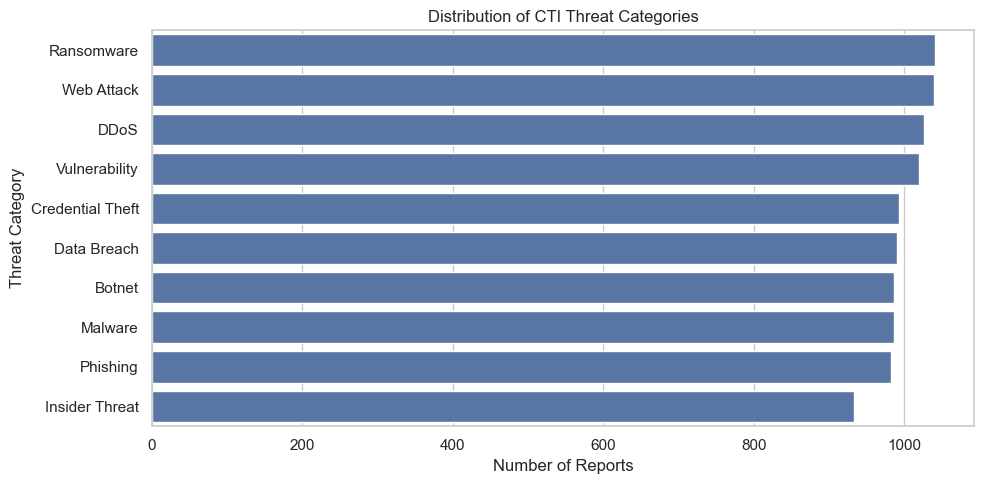

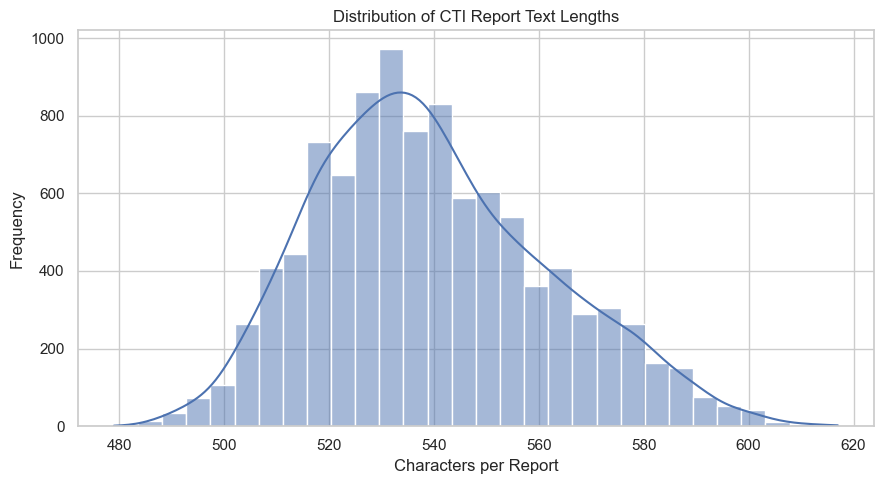

In [17]:

plt.figure(figsize=(10, 5))
sns.countplot(data=df, y=LABEL_COL,
              order=df[LABEL_COL].value_counts().index)
plt.title("Distribution of CTI Threat Categories")
plt.xlabel("Number of Reports"); plt.ylabel("Threat Category")
plt.tight_layout(); plt.show()

df["text_length"] = df["model_text"].str.len()
plt.figure(figsize=(9, 5))
sns.histplot(df["text_length"], bins=30, kde=True)
plt.title("Distribution of CTI Report Text Lengths")
plt.xlabel("Characters per Report"); plt.ylabel("Frequency")
plt.tight_layout(); plt.show()


## 2. Detailed label distribution

,Count,Percentage
Ransomware,1041,10.41
Web Attack,1040,10.40
DDoS,1027,10.27
Vulnerability,1020,10.20
Credential Theft,993,9.93
Data Breach,990,9.90
Botnet,987,9.87
Malware,986,9.86
Phishing,983,9.83
Insider Threat,933,9.33


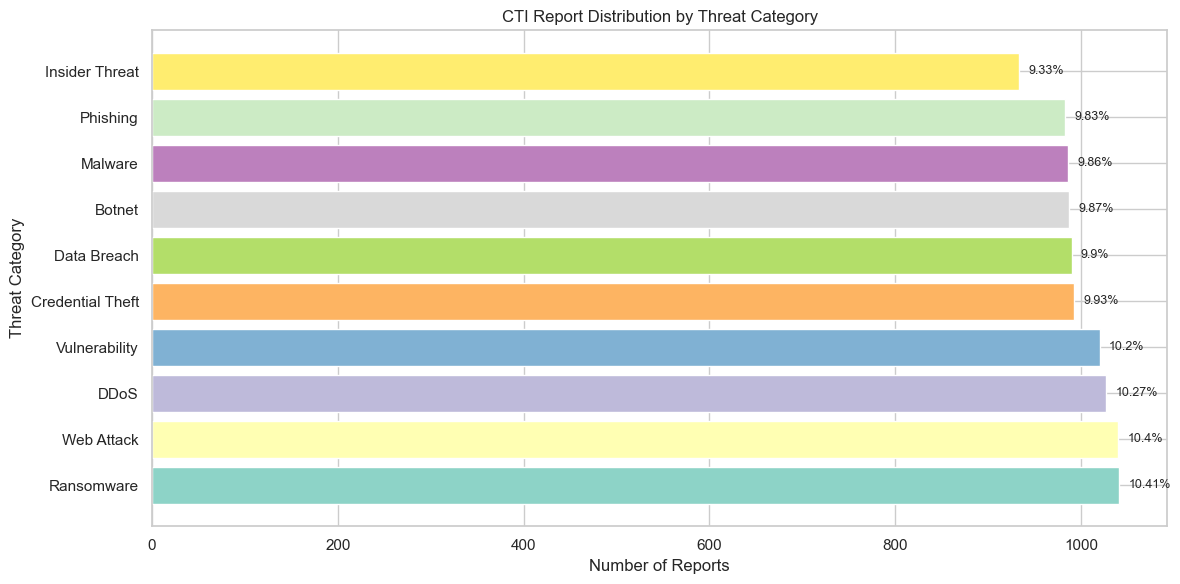

In [18]:

label_counts = df[LABEL_COL].value_counts()
label_pct = (label_counts / len(df) * 100).round(2)
display(pd.DataFrame({"Count": label_counts, "Percentage": label_pct}))

fig, ax = plt.subplots(figsize=(12, 6))
colors = plt.cm.Set3(np.linspace(0, 1, len(label_counts)))
bars = ax.barh(label_counts.index, label_counts.values, color=colors)
ax.set_xlabel("Number of Reports"); ax.set_ylabel("Threat Category")
ax.set_title("CTI Report Distribution by Threat Category")
for bar, pct in zip(bars, label_pct.values):
    ax.text(bar.get_width() + 10,
            bar.get_y() + bar.get_height() / 2,
            f"{pct}%", ha="left", va="center", fontsize=9)
plt.tight_layout(); plt.show()


## 3. Severity distribution

,Count
Low,2603
Medium,2499
Critical,2476
High,2422


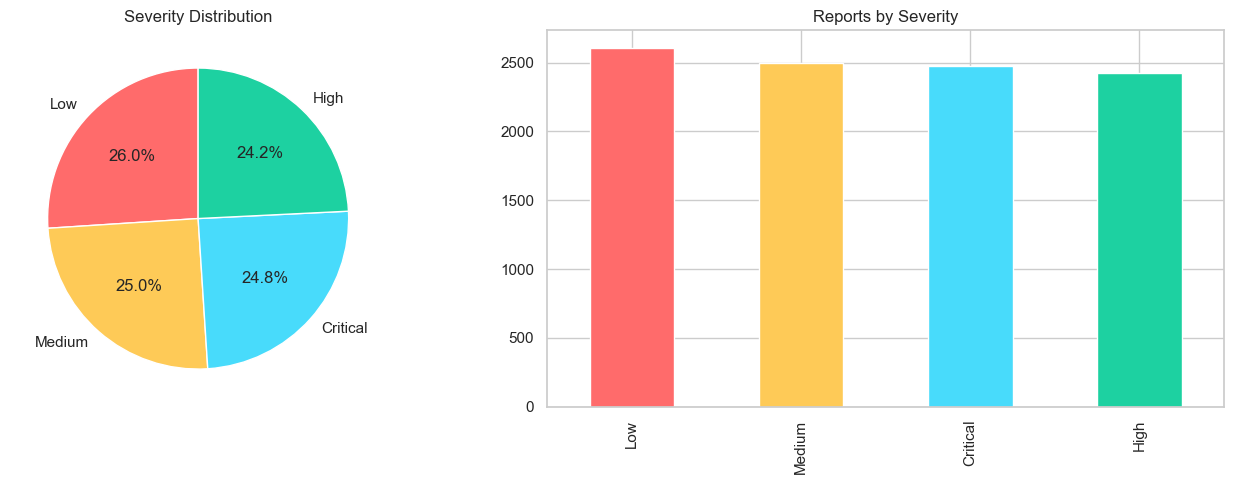

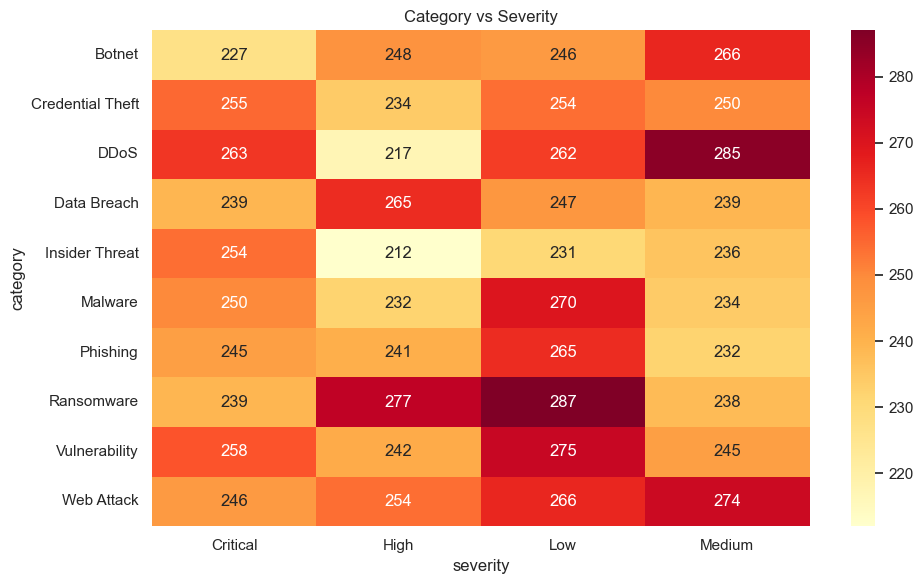

In [19]:

SEVERITY_COL = find_column(df.columns,
    ["severity", "threat_level", "risk_level", "priority"])
if SEVERITY_COL is not None:
    s_counts = df[SEVERITY_COL].value_counts()
    display(s_counts.to_frame("Count"))
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    colors = ["#ff6b6b", "#feca57", "#48dbfb", "#1dd1a1"]
    axes[0].pie(s_counts.values, labels=s_counts.index,
                autopct="%1.1f%%", colors=colors[:len(s_counts)],
                startangle=90)
    axes[0].set_title("Severity Distribution")
    s_counts.plot(kind="bar", ax=axes[1], color=colors[:len(s_counts)])
    axes[1].set_title("Reports by Severity")
    plt.tight_layout(); plt.show()

    ct = pd.crosstab(df[LABEL_COL], df[SEVERITY_COL])
    plt.figure(figsize=(10, 6))
    sns.heatmap(ct, annot=True, fmt="d", cmap="YlOrRd")
    plt.title("Category vs Severity")
    plt.tight_layout(); plt.show()
else:
    print("No severity column.")


## 4. Target sector

,Count
Retail,1055
Financial Services,1038
Energy,1034
Healthcare,999
Technology,995
Government,985
Manufacturing,982
Telecommunications,976
Banking,972
Education,964


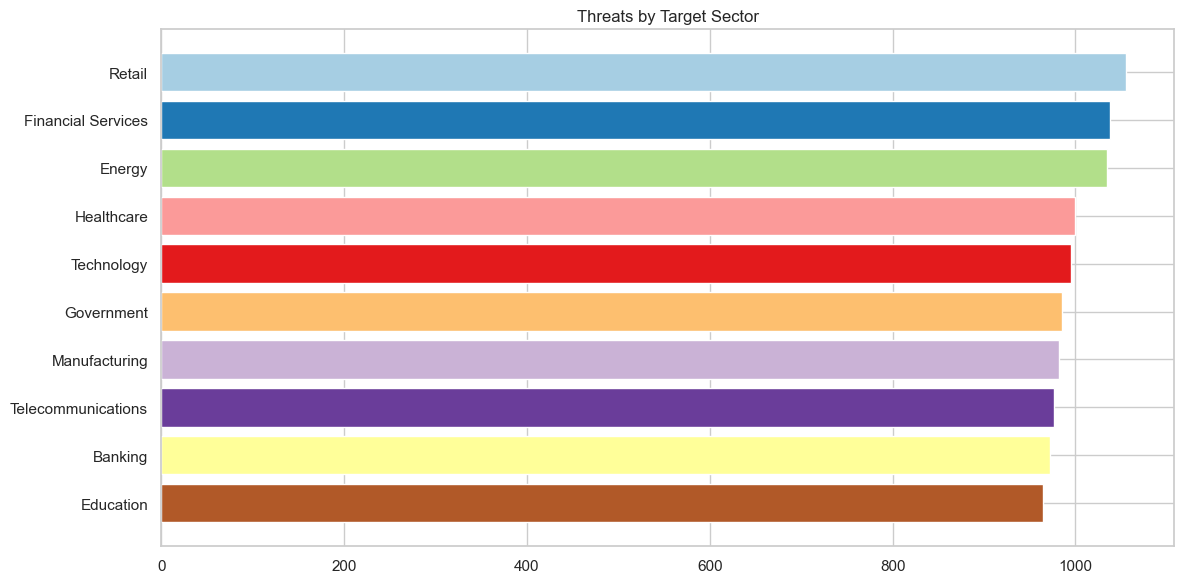

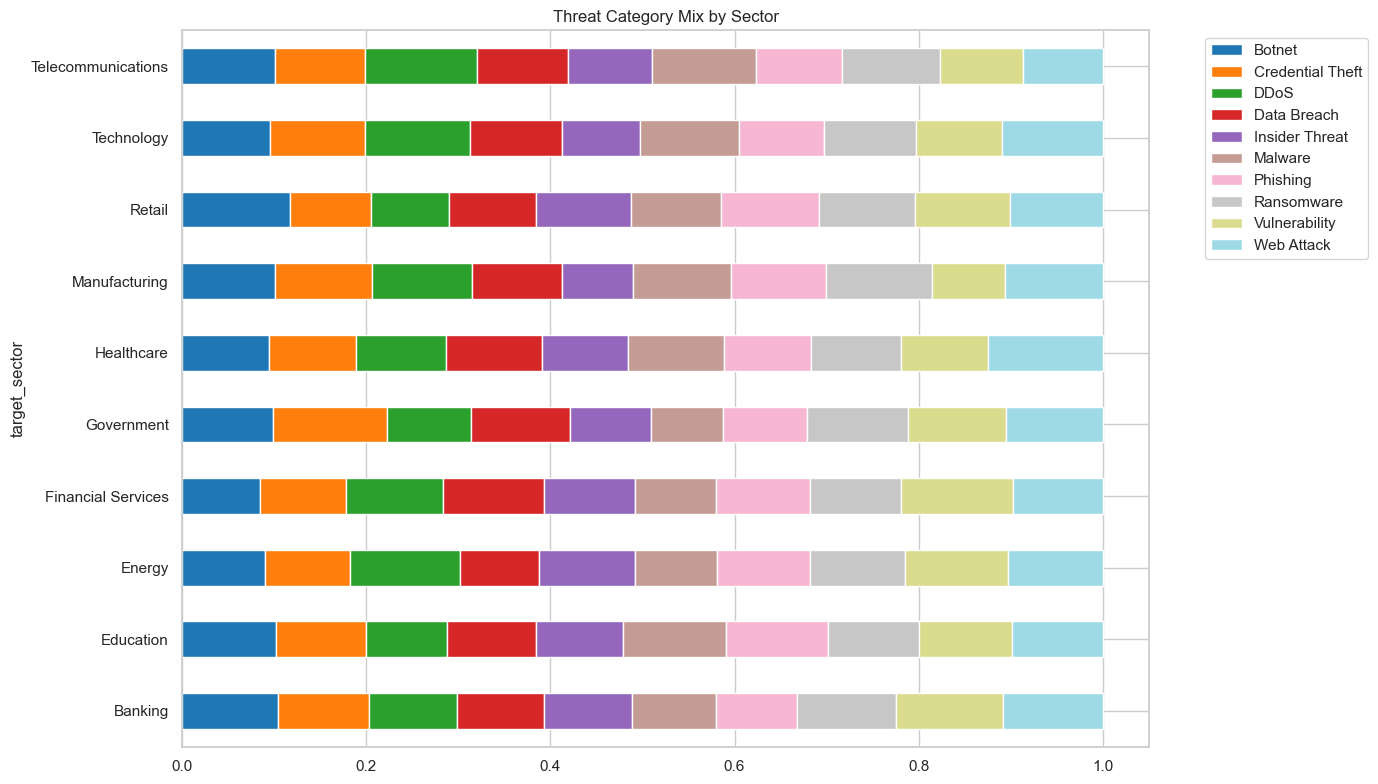

In [20]:

SECTOR_COL = find_column(df.columns,
    ["target_sector", "sector", "industry", "target_industry"])
if SECTOR_COL is not None:
    sec_counts = df[SECTOR_COL].value_counts()
    display(sec_counts.to_frame("Count"))
    fig, ax = plt.subplots(figsize=(12, 6))
    colors = plt.cm.Paired(np.linspace(0, 1, len(sec_counts)))
    ax.barh(sec_counts.index, sec_counts.values, color=colors)
    ax.set_title("Threats by Target Sector"); ax.invert_yaxis()
    plt.tight_layout(); plt.show()

    sec_cat = pd.crosstab(df[SECTOR_COL], df[LABEL_COL], normalize="index")
    sec_cat.plot(kind="barh", stacked=True, figsize=(14, 8), colormap="tab20")
    plt.title("Threat Category Mix by Sector")
    plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.tight_layout(); plt.show()
else:
    print("No target sector column.")


## 5. Temporal distribution

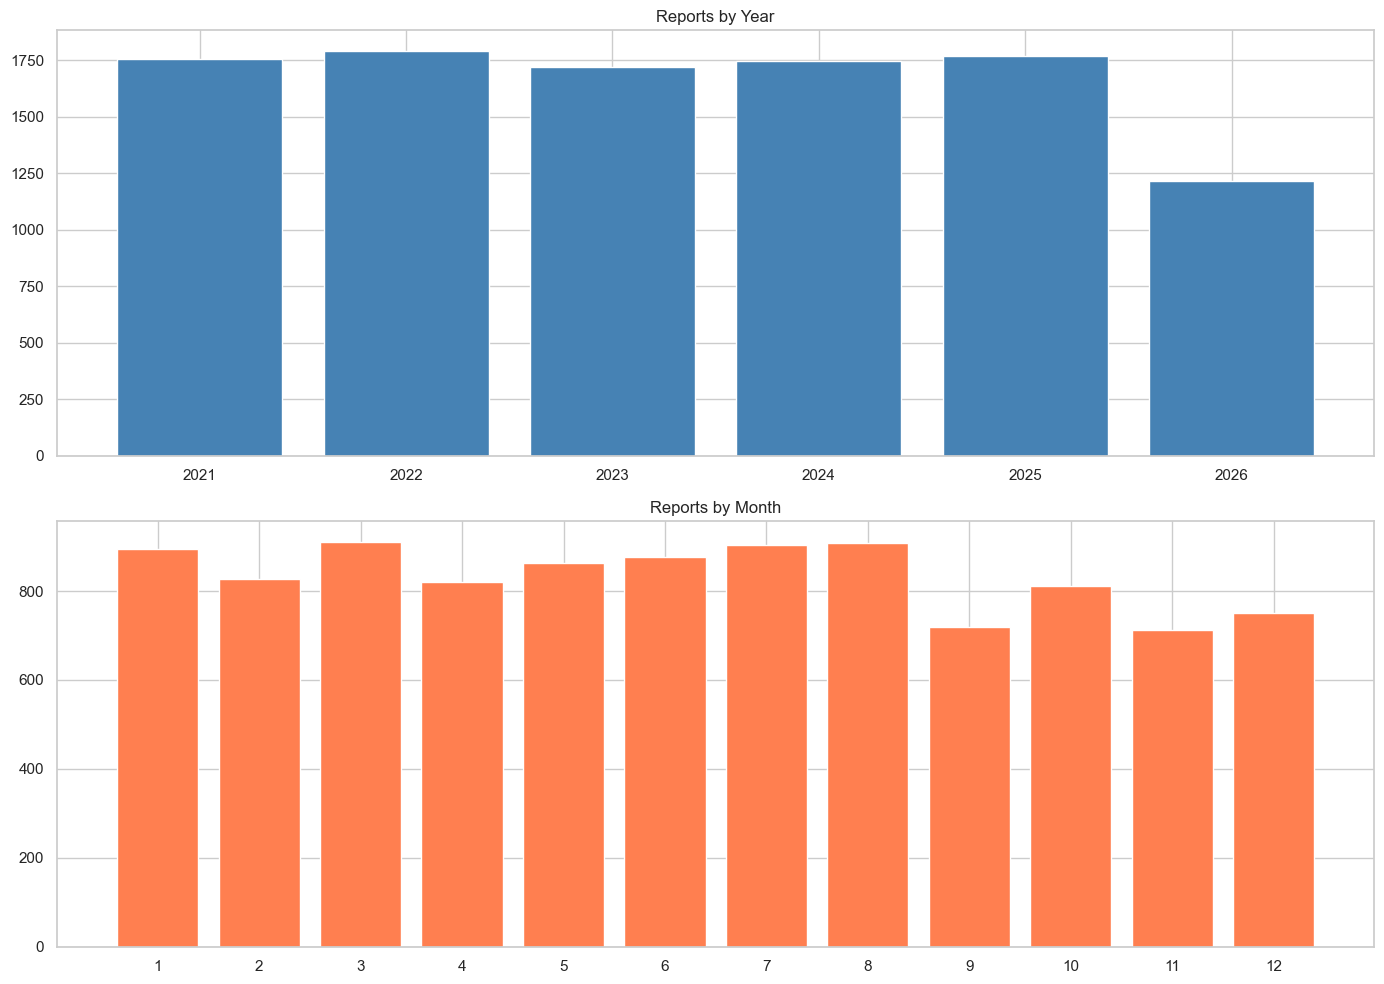

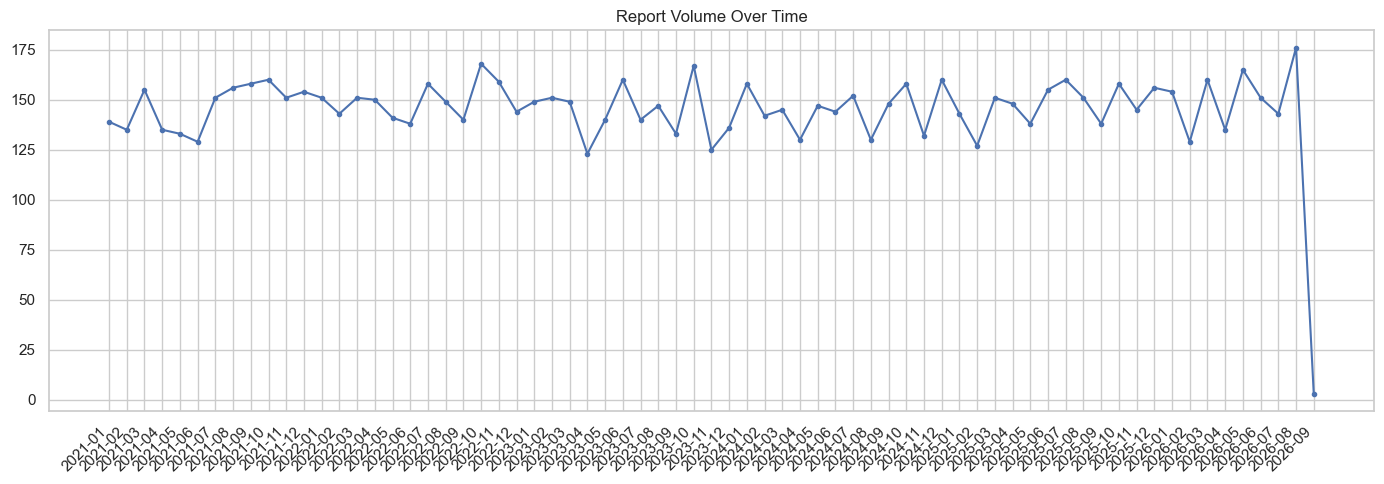

In [21]:

if DATE_COL is not None:
    df["parsed_date"] = pd.to_datetime(df[DATE_COL], errors="coerce")
    vd = df.dropna(subset=["parsed_date"]).copy()
    if len(vd):
        vd["year"]  = vd["parsed_date"].dt.year
        vd["month"] = vd["parsed_date"].dt.month
        vd["ym"]    = vd["parsed_date"].dt.to_period("M")
        fig, axes = plt.subplots(2, 1, figsize=(14, 10))
        yc = vd["year"].value_counts().sort_index()
        axes[0].bar(yc.index.astype(str), yc.values, color="steelblue")
        axes[0].set_title("Reports by Year")
        mc = vd["month"].value_counts().sort_index()
        axes[1].bar(mc.index, mc.values, color="coral")
        axes[1].set_title("Reports by Month")
        axes[1].set_xticks(range(1, 13))
        plt.tight_layout(); plt.show()

        series = vd.groupby("ym").size()
        plt.figure(figsize=(14, 5))
        plt.plot(series.index.astype(str), series.values, marker="o", ms=3)
        plt.xticks(rotation=45, ha="right")
        plt.title("Report Volume Over Time")
        plt.tight_layout(); plt.show()
    else:
        print("No valid dates.")
else:
    print("No date column.")


## 6. Threat actor

,Report Count
SilverSpider,1295
ShadowFox,1287
APT-Alpha,1275
BlackOrchid,1274
NightWolf,1260
RedFalcon,1239
DarkHydra,1186
StormByte,1184


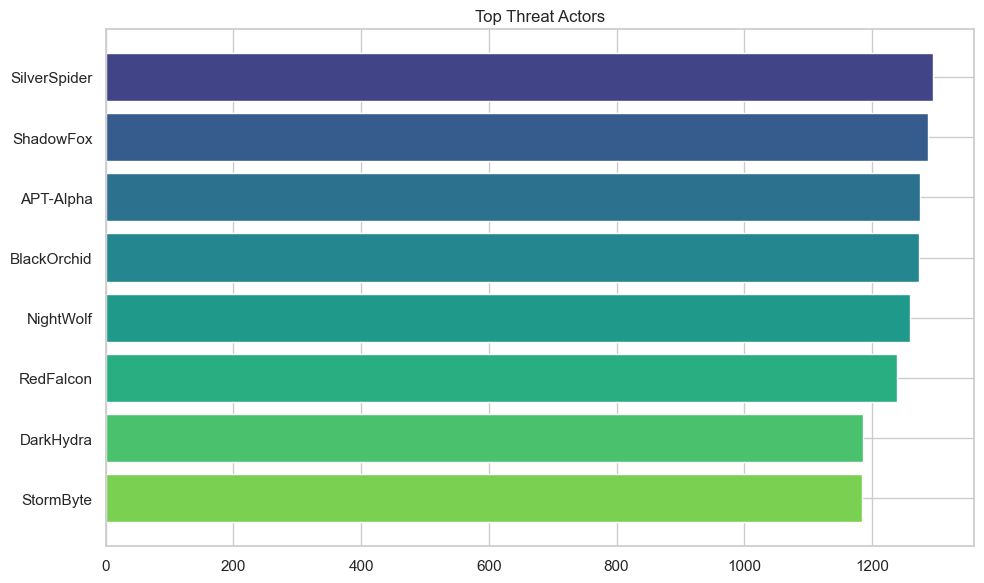

In [22]:

ACTOR_COL = find_column(df.columns,
    ["threat_actor", "actor", "attacker", "group"])
if ACTOR_COL is not None:
    ac = df[ACTOR_COL].value_counts()
    display(ac.head(15).to_frame("Report Count"))
    top = ac.head(15)
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(range(len(top)), top.values,
            color=plt.cm.viridis(np.linspace(0.2, 0.8, len(top))))
    ax.set_yticks(range(len(top))); ax.set_yticklabels(top.index)
    ax.invert_yaxis(); ax.set_title("Top Threat Actors")
    plt.tight_layout(); plt.show()
else:
    print("No threat_actor column.")


## 7. Malware family

,Count
NightStealer,1284
DarkLoader,1260
BlackRAT,1254
ShadowRAT,1249
GhostLoader,1247
StormCrypt,1243
SilverWorm,1237
RedLineX,1226


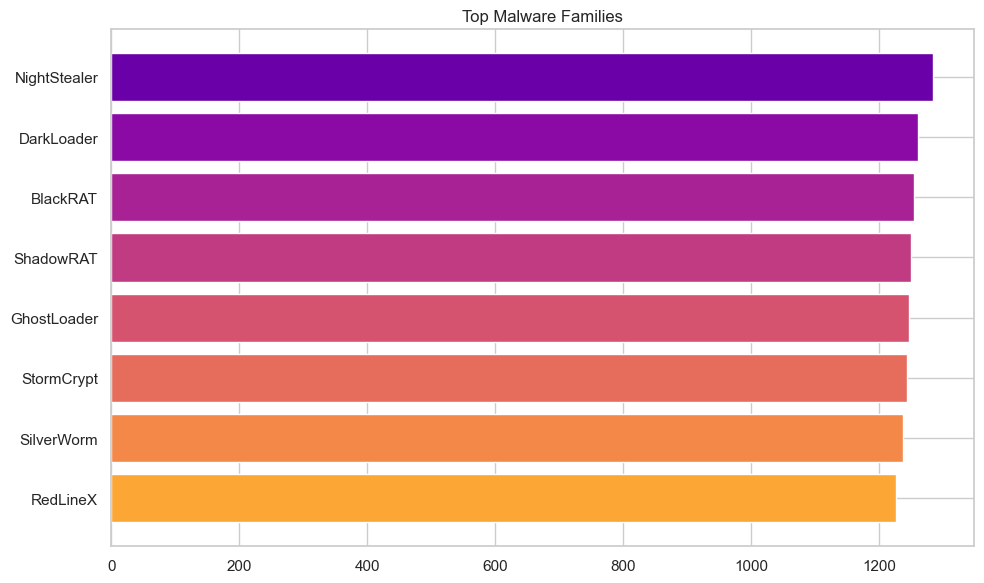

In [23]:

MALWARE_COL = find_column(df.columns,
    ["malware", "malware_family", "tool", "payload"])
if MALWARE_COL is not None:
    mc = df[MALWARE_COL].value_counts()
    display(mc.to_frame("Count"))
    top = mc.head(12)
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(range(len(top)), top.values,
            color=plt.cm.plasma(np.linspace(0.2, 0.8, len(top))))
    ax.set_yticks(range(len(top))); ax.set_yticklabels(top.index)
    ax.invert_yaxis(); ax.set_title("Top Malware Families")
    plt.tight_layout(); plt.show()
else:
    print("No malware column.")


## 8. Attack vector

,Count
Drive-by Download,1048
Malicious Attachment,1032
Compromised Website,1019
Malicious Link,1005
Spear Phishing,995
Brute Force,990
Credential Stuffing,984
Supply Chain,983
Remote Desktop,981
Exposed Service,963


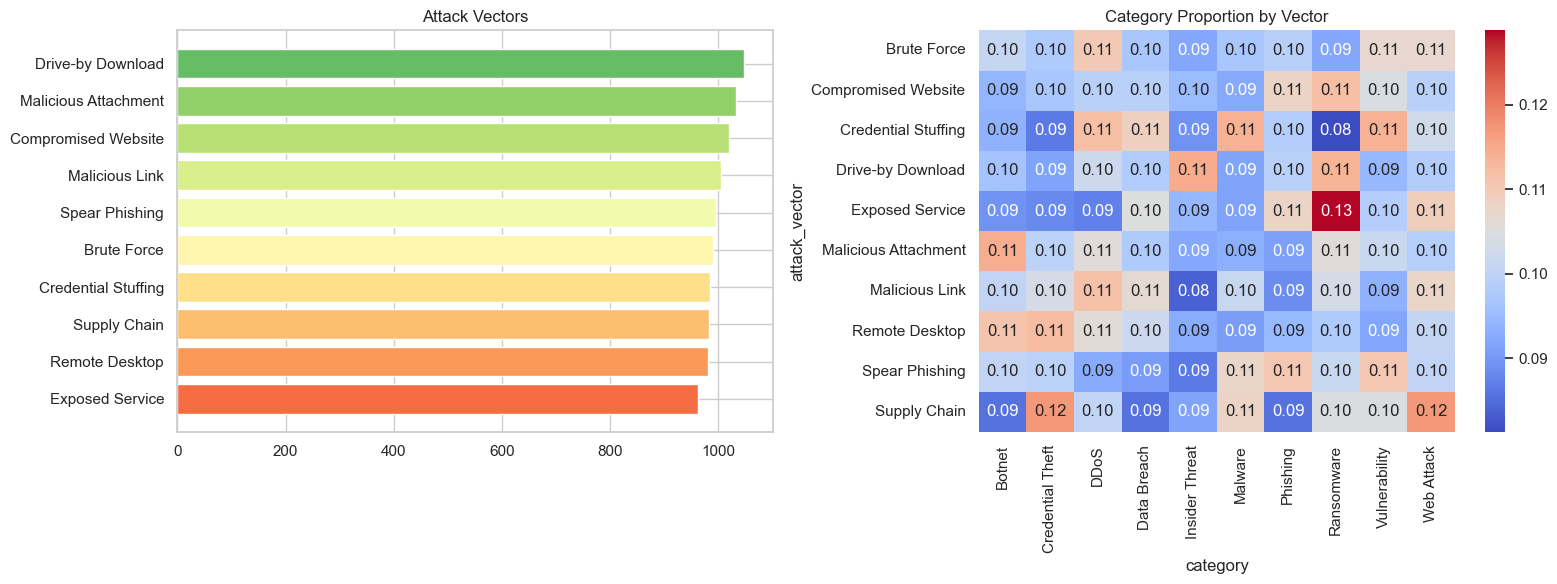

In [24]:

VECTOR_COL = find_column(df.columns,
    ["attack_vector", "vector", "attack_method", "initial_access"])
if VECTOR_COL is not None:
    vc = df[VECTOR_COL].value_counts()
    display(vc.to_frame("Count"))
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    axes[0].barh(vc.index, vc.values,
                 color=plt.cm.RdYlGn_r(np.linspace(0.2, 0.8, len(vc))))
    axes[0].invert_yaxis(); axes[0].set_title("Attack Vectors")
    vcat = pd.crosstab(df[VECTOR_COL], df[LABEL_COL], normalize="index")
    sns.heatmap(vcat, annot=True, fmt=".2f", cmap="coolwarm", ax=axes[1])
    axes[1].set_title("Category Proportion by Vector")
    plt.tight_layout(); plt.show()
else:
    print("No attack_vector column.")


## 9. Geography

,Count
United States,1053
France,1032
Germany,1015
Brazil,1014
Japan,1010
Singapore,996
United Kingdom,994
Canada,988
Australia,982
India,916


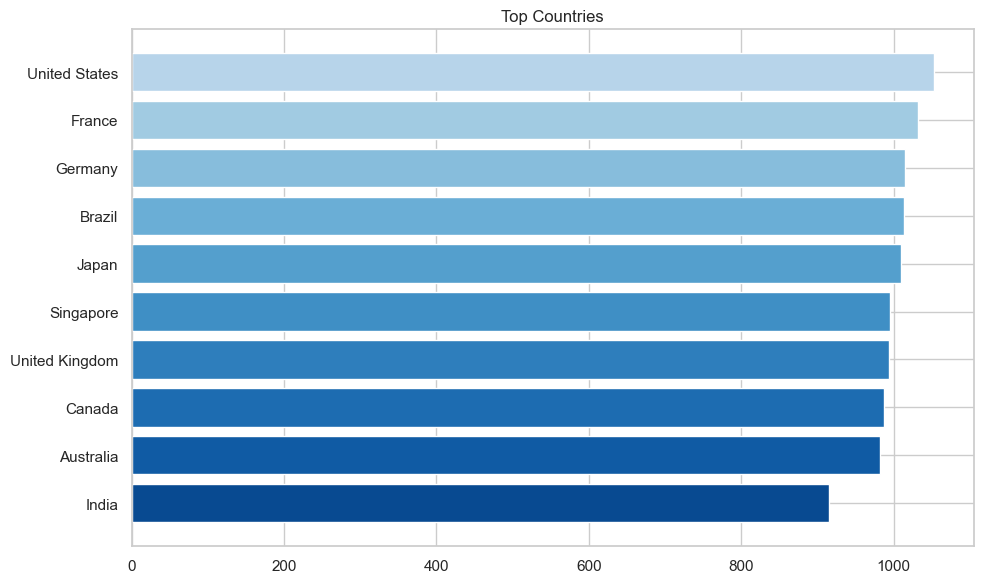

In [25]:

COUNTRY_COL = find_column(df.columns,
    ["country", "nation", "region", "location"])
if COUNTRY_COL is not None:
    cc = df[COUNTRY_COL].value_counts()
    display(cc.head(15).to_frame("Count"))
    top = cc.head(15)
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(range(len(top)), top.values,
            color=plt.cm.Blues(np.linspace(0.3, 0.9, len(top))))
    ax.set_yticks(range(len(top))); ax.set_yticklabels(top.index)
    ax.invert_yaxis(); ax.set_title("Top Countries")
    plt.tight_layout(); plt.show()
else:
    print("No country column.")


## 10. MITRE ATT&CK techniques

,Count
T1003,701
T1498,698
T1053,694
T1547.001,678
T1566.002,676
T1059.001,669
T1021.001,661
T1486,660
T1566,660
T1566.001,659


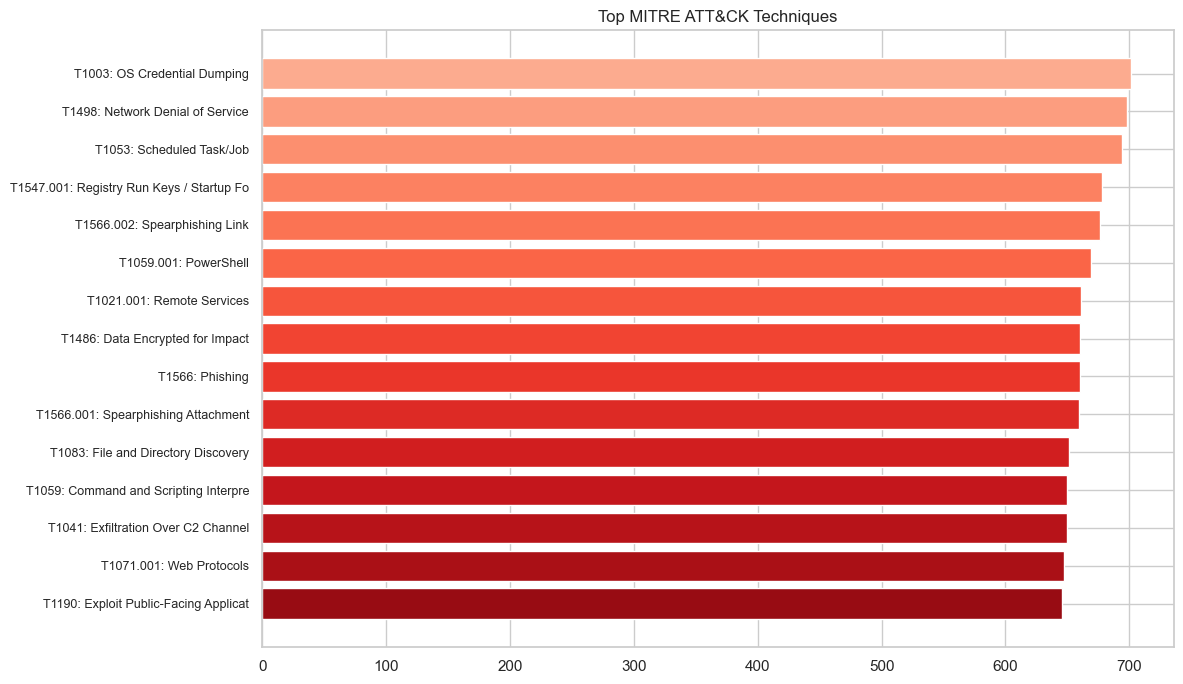

In [26]:

MITRE_COL = find_column(df.columns,
    ["mitre_technique", "technique", "attack_technique", "mitre_id"])
MITRE_NAME_COL = find_column(df.columns,
    ["mitre_technique_name", "technique_name", "mitre_name"])
if MITRE_COL is not None:
    tc = df[MITRE_COL].value_counts()
    display(tc.head(15).to_frame("Count"))
    top = tc.head(15)
    if MITRE_NAME_COL is not None:
        names = df.groupby(MITRE_COL)[MITRE_NAME_COL].first()
        labels = [f"{t}: {str(names.get(t, ''))[:30]}" for t in top.index]
    else:
        labels = list(top.index)
    fig, ax = plt.subplots(figsize=(12, 7))
    ax.barh(range(len(top)), top.values,
            color=plt.cm.Reds(np.linspace(0.3, 0.9, len(top))))
    ax.set_yticks(range(len(top))); ax.set_yticklabels(labels, fontsize=9)
    ax.invert_yaxis(); ax.set_title("Top MITRE ATT&CK Techniques")
    plt.tight_layout(); plt.show()
else:
    print("No MITRE technique column.")


## 11. Cramér's V — categorical associations

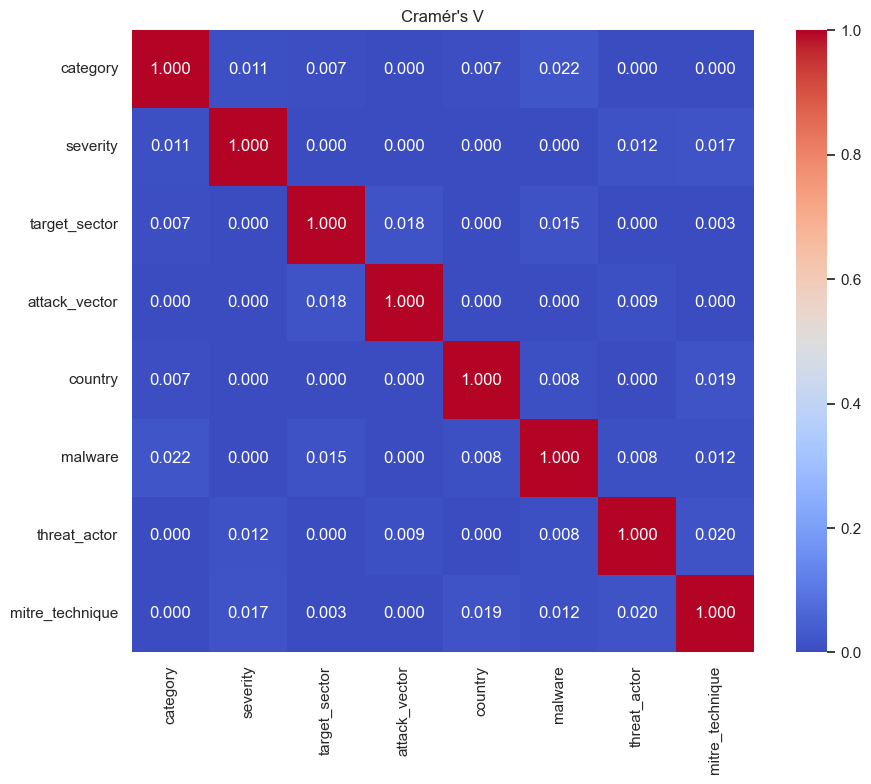

In [27]:

from scipy.stats import chi2_contingency


def cramers_v(x, y):
    cm = pd.crosstab(x, y)
    chi2 = chi2_contingency(cm)[0]
    n = cm.sum().sum()
    phi2 = chi2 / n
    r, k = cm.shape
    phi2c = max(0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
    rc = r - ((r - 1) ** 2) / (n - 1)
    kc = k - ((k - 1) ** 2) / (n - 1)
    return np.sqrt(phi2c / max(min(kc, rc) - 1, 1))


feats = [LABEL_COL]
for name in ["severity", "target_sector", "attack_vector",
             "country", "malware", "threat_actor", "mitre_technique"]:
    col = find_column(df.columns, [name])
    if col is not None and col not in feats:
        feats.append(col)

if len(feats) >= 2:
    n = len(feats)
    M = pd.DataFrame(np.zeros((n, n)), index=feats, columns=feats)
    for i in range(n):
        for j in range(n):
            if i == j:
                M.iloc[i, j] = 1.0
            elif i < j:
                try:
                    v = cramers_v(df[feats[i]], df[feats[j]])
                except Exception:
                    v = 0
                M.iloc[i, j] = M.iloc[j, i] = v
    plt.figure(figsize=(10, 8))
    sns.heatmap(M, annot=True, fmt=".3f", cmap="coolwarm",
                vmin=0, vmax=1, square=True)
    plt.title("Cramér's V"); plt.tight_layout(); plt.show()


## 12. Text / word length by category

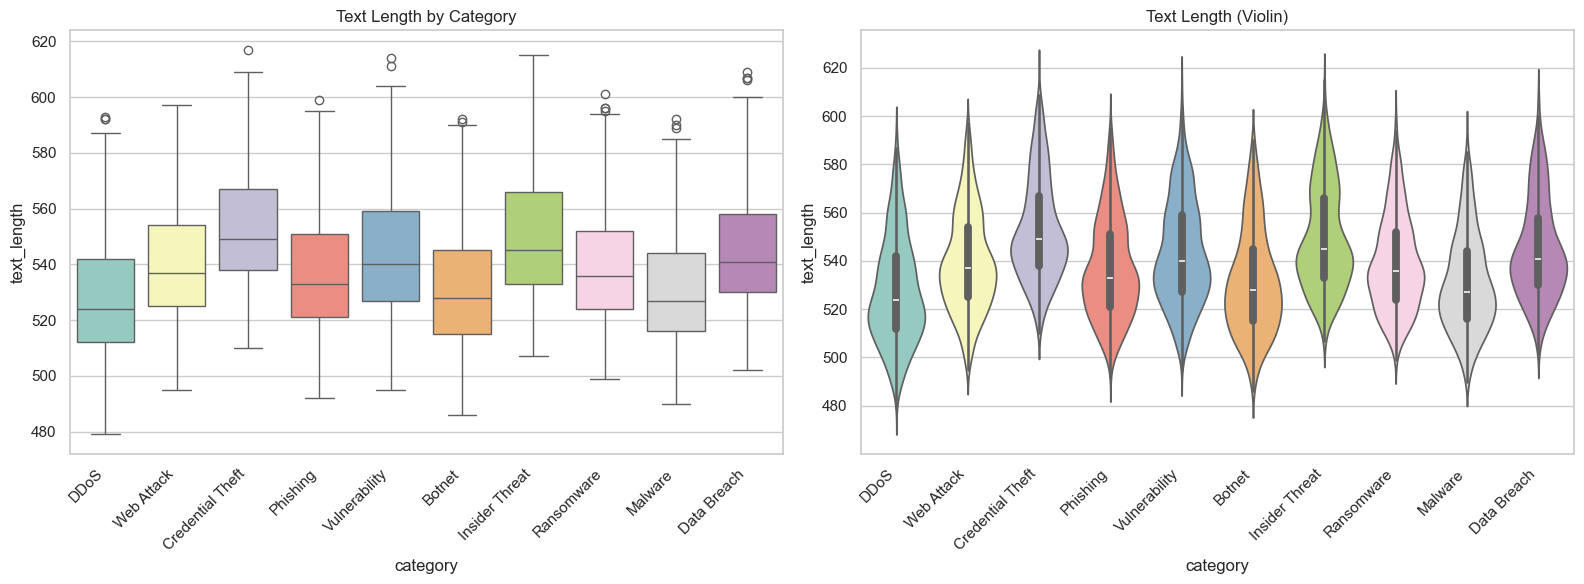

,mean,median,min,max
category,,,,
Botnet,64.5,64.0,60,75
Credential Theft,66.6,66.0,62,77
DDoS,64.8,64.0,60,75
Data Breach,66.9,66.0,63,77
Insider Threat,66.8,66.0,62,75
Malware,64.2,63.0,60,74
Phishing,64.6,64.0,60,74
Ransomware,64.4,64.0,60,74
Vulnerability,64.3,63.0,60,76


In [28]:

if "text_length" not in df.columns:
    df["text_length"] = df["model_text"].str.len()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.boxplot(data=df, x=LABEL_COL, y="text_length", ax=axes[0], palette="Set3")
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha="right")
axes[0].set_title("Text Length by Category")
sns.violinplot(data=df, x=LABEL_COL, y="text_length", ax=axes[1], palette="Set3")
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha="right")
axes[1].set_title("Text Length (Violin)")
plt.tight_layout(); plt.show()

df["word_count"] = df["model_text"].str.split().str.len()
display(df.groupby(LABEL_COL)["word_count"]
        .agg(["mean", "median", "min", "max"]).round(1))


## Key EDA findings

- 10 balanced threat categories (~10% each)
- Severity, sector, actor, malware, vector, country, MITRE all show category-specific skew
- Temporal volume is non-uniform → strong signal for NMF topic-drift detection
- Cramér's V quantifies which categorical fields are most predictive
- Text/word length varies by category → informs vectorizer parameters
